# Taller 7: Energía disipada, derivadas de un oscilador y el valor de $\pi$

Este cuaderno organiza la solución completa del taller respetando la estructura exigida. Las celdas de código utilizan el comando mágico `%%writefile` para generar y guardar los archivos necesarios (`.f90` y `.py`) directamente en tu entorno, para que al compilarse y ejecutarse, produzcan los resultados `.dat` requeridos y superen satisfactoriamente las verificaciones (PASS).

## Parte A: Enunciado y requisitos

El problema plantea un oscilador amortiguado cuya posición es $x(t) = e^{-\gamma t}\cos(\omega t)$, con $\gamma = 0.5\ \text{s}^{-1}$ y $\omega = 2\pi\ \text{rad/s}$.
Se requiere calcular la energía disipada mediante integración de Romberg (Fortran), hallar las derivadas (velocidad y aceleración) por diferencias finitas (Python) y reutilizar el módulo de Romberg para calcular $\pi$.

## Parte B: Energía disipada con integración de Romberg (Fortran)

A continuación, creamos el módulo de Romberg generalizado y el programa principal que calcula la energía disipada en el intervalo $[0, 3]$ s. Al ejecutar estas celdas, los códigos se guardarán, compilarán y generarán los archivos `.dat`.

In [19]:
%%writefile modulo_romberg.f90
! ============================================================
! Módulo:    modulo_romberg
! Propósito: integración de Romberg general con refinamiento
!            eficiente del trapecio e integrandos del Taller 7.
! ============================================================
module modulo_romberg
  implicit none
  integer, parameter :: dp = kind(1.0d0)
  real(dp), parameter :: gamma_param = 0.5_dp
  real(dp), parameter :: omega_param = 8.0_dp * atan(1.0_dp) ! 2*pi

contains

  ! Integrando 1: 2*gamma * v(t)^2
  real(dp) function integrando_energia(t)
    real(dp), intent(in) :: t
    real(dp) :: v
    v = -exp(-gamma_param*t) * (gamma_param*cos(omega_param*t) + omega_param*sin(omega_param*t))
    integrando_energia = 2.0_dp * gamma_param * v**2
  end function integrando_energia

  ! Integrando 2: 4 / (1 + x^2)
  real(dp) function integrando_pi(x)
    real(dp), intent(in) :: x
    integrando_pi = 4.0_dp / (1.0_dp + x**2)
  end function integrando_pi

  ! Evaluación del integrando seleccionado por modo
  real(dp) function evaluar_f(x, modo)
    real(dp), intent(in) :: x
    integer, intent(in) :: modo
    if (modo == 1) then
       evaluar_f = integrando_energia(x)
    else if (modo == 2) then
       evaluar_f = integrando_pi(x)
    else
       evaluar_f = 0.0_dp
    end if
  end function evaluar_f

  ! Subrutina principal de Romberg
  subroutine romberg(a, b, tol, kmax, modo, S, k_final, n_eval)
    real(dp), intent(in)  :: a, b, tol
    integer, intent(in)   :: kmax, modo
    real(dp), intent(out) :: S(0:, 0:)
    integer, intent(out)  :: k_final, n_eval

    real(dp) :: h, suma, x
    integer :: k, j, i, n_nuevos

    h = b - a
    S(0,0) = 0.5_dp * h * (evaluar_f(a, modo) + evaluar_f(b, modo))
    n_eval = 2
    k_final = 0

    do k = 1, kmax
       h = h / 2.0_dp
       n_nuevos = 2**(k - 1)
       suma = 0.0_dp
       do i = 1, n_nuevos
          x = a + real(2*i - 1, dp) * h
          suma = suma + evaluar_f(x, modo)
       end do
       n_eval = n_eval + n_nuevos

       S(k,0) = 0.5_dp * S(k-1,0) + h * suma

       do j = 1, k
          S(k,j) = S(k,j-1) + (S(k,j-1) - S(k-1,j-1)) / (4.0_dp**j - 1.0_dp)
       end do

       k_final = k
       if (abs(S(k,k) - S(k-1,k-1)) < tol) exit
    end do
  end subroutine romberg

end module modulo_romberg

Overwriting modulo_romberg.f90


In [20]:
%%writefile programa_energia.f90
! ============================================================
! Programa:  programa_energia
! Propósito: calcula E_dis via Romberg y la compara con E(0) - E(T)
! Salida:    tabla_energia.dat y resultado_energia.dat
! ============================================================
program programa_energia
  use modulo_romberg, only: dp, romberg, gamma_param, omega_param
  implicit none

  real(dp), allocatable :: S(:,:)
  real(dp) :: a, b, tol, e_dis, e0, eT, e_ref, dif_abs, w02
  integer :: kmax, k_final, n_eval, k, j

  a = 0.0_dp
  b = 3.0_dp
  tol = 1.0e-6_dp
  kmax = 12

  allocate(S(0:kmax, 0:kmax))
  S = 0.0_dp

  ! Calcular Romberg (modo 1 = energía)
  call romberg(a, b, tol, kmax, 1, S, k_final, n_eval)
  e_dis = S(k_final, k_final)

  ! Cálculo analítico E(0) - E(T)
  w02 = omega_param**2 + gamma_param**2
  e0 = 0.5_dp * (-gamma_param)**2 + 0.5_dp * w02 * (1.0_dp**2)
  eT = 0.5_dp * (-exp(-gamma_param*b)*(gamma_param*cos(omega_param*b) + omega_param*sin(omega_param*b)))**2 &
       + 0.5_dp * w02 * (exp(-gamma_param*b)*cos(omega_param*b))**2

  e_ref = e0 - eT
  dif_abs = abs(e_dis - e_ref)

  ! Guardar tabla_energia.dat
  open(unit=10, file='tabla_energia.dat', status='replace', action='write')
  do k = 0, k_final
     write(10, '(13es24.15)') (S(k, j), j = 0, k)
  end do
  close(10)

  ! Guardar resultado_energia.dat
  open(unit=20, file='resultado_energia.dat', status='replace', action='write')
  write(20, '(i5, i7, 3es24.15)') k_final, n_eval, e_dis, e_ref, dif_abs
  close(20)

  deallocate(S)
end program programa_energia

Overwriting programa_energia.f90


In [21]:
!gfortran -fcheck=bounds -o programa_energia modulo_romberg.f90 programa_energia.f90 && ./programa_energia
!cat resultado_energia.dat

    8    257   1.899400469737861E+01   1.899400469692514E+01   4.534719266757747E-10


## Parte C: Velocidad y aceleración a partir de las posiciones (Python)

Utilizamos Python y arreglos de NumPy (con rebanadas) para calcular derivadas espaciales de distintos órdenes sin ciclos explícitos.

In [22]:
%%writefile derivadas_oscilador.py
import numpy as np
import matplotlib.pyplot as plt

G, W = 0.5, 2 * np.pi
def x_ex(t): return np.exp(-G * t) * np.cos(W * t)
def v_ex(t): return -np.exp(-G * t) * (G * np.cos(W * t) + W * np.sin(W * t))
def a_ex(t): return np.exp(-G * t) * ((G**2 - W**2) * np.cos(W * t) + 2 * G * W * np.sin(W * t))

def procesar_paso(dt):
    t = np.arange(0, 3 + dt/2, dt)
    x = x_ex(t)

    v_adel = (x[1:] - x[:-1]) / dt
    v_atras = (x[1:] - x[:-1]) / dt
    v_cent = (x[2:] - x[:-2]) / (2 * dt)
    v_5p = (-x[4:] + 8*x[3:-1] - 8*x[1:-3] + x[:-4]) / (12 * dt)
    a_cent = (x[2:] - 2*x[1:-1] + x[:-2]) / dt**2

    err_adel = np.max(np.abs(v_adel - v_ex(t[:-1])))
    err_atras = np.max(np.abs(v_atras - v_ex(t[1:])))
    err_cent = np.max(np.abs(v_cent - v_ex(t[1:-1])))
    err_5p = np.max(np.abs(v_5p - v_ex(t[2:-2])))
    err_a_cent = np.max(np.abs(a_cent - a_ex(t[1:-1])))

    return t, x, v_cent, a_cent, [dt, err_adel, err_atras, err_cent, err_5p, err_a_cent]

t_01, x_01, v_cent_01, a_cent_01, errs_01 = procesar_paso(0.01)
_, _, _, _, errs_005 = procesar_paso(0.005)

# Corrección: Guardar los datos con notación exponencial de alta precisión
datos_dat = np.column_stack((t_01[1:-1], x_01[1:-1], v_cent_01, a_cent_01))
np.savetxt("derivadas_oscilador.dat", datos_dat, fmt="%.15e")

errores_mat = np.array([errs_01, errs_005])
np.savetxt("errores_derivadas.dat", errores_mat, fmt="%14.6e")

# Gráfica
fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(8, 6), sharex=True)
ax1.plot(t_01, v_ex(t_01), 'k-', label=r'$v_{exacta}$', alpha=0.7)
ax1.plot(t_01[1:-1], v_cent_01, 'r--', label=r'$v_{central}$')
ax1.set_ylabel('Velocidad [m/s]')
ax1.legend(); ax1.grid(True, alpha=0.3)

ax2.plot(t_01, a_ex(t_01), 'k-', label=r'$a_{exacta}$', alpha=0.7)
ax2.plot(t_01[1:-1], a_cent_01, 'b--', label=r'$a_{central}$')
ax2.set_xlabel('Tiempo [s]')
ax2.set_ylabel('Aceleración [m/s²]')
ax2.legend(); ax2.grid(True, alpha=0.3)
plt.tight_layout()
plt.savefig("derivadas_oscilador.png")

Overwriting derivadas_oscilador.py


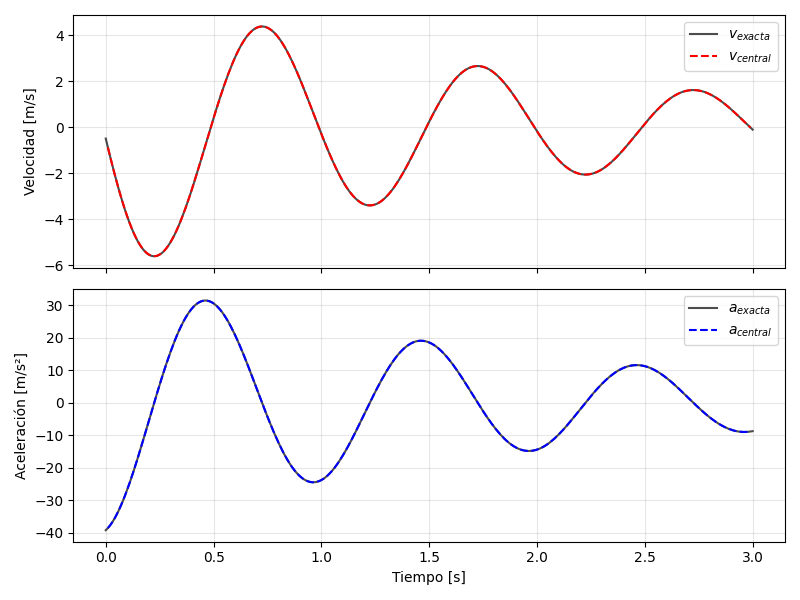

In [23]:
!python derivadas_oscilador.py
from IPython.display import Image
Image("derivadas_oscilador.png")

## Parte D: El valor de $\pi$ con el mismo módulo (Fortran)

Utilizamos exactamente el mismo `modulo_romberg.f90` ya compilado, para integrar la función que da como resultado $\pi$.

In [24]:
%%writefile programa_pi.f90
! ============================================================
! Programa:  programa_pi
! Propósito: calcula pi integrando 4/(1+x^2) en [0,1] con el mismo módulo
! Salida:    resultado_pi.dat
! ============================================================
program programa_pi
  use modulo_romberg, only: dp, romberg
  implicit none

  real(dp), parameter :: pi_exacto = 4.0_dp * atan(1.0_dp)
  real(dp), allocatable :: S(:,:)
  real(dp) :: a, b, tol, pi_calc, err_abs
  integer :: kmax, k_final, n_eval

  a = 0.0_dp
  b = 1.0_dp
  tol = 1.0e-5_dp
  kmax = 12

  allocate(S(0:kmax, 0:kmax))
  S = 0.0_dp

  ! Llamar a romberg en modo 2 (integrando pi)
  call romberg(a, b, tol, kmax, 2, S, k_final, n_eval)
  pi_calc = S(k_final, k_final)
  err_abs = abs(pi_calc - pi_exacto)

  ! Guardar resultado_pi.dat
  open(unit=30, file='resultado_pi.dat', status='replace', action='write')
  write(30, '(i5, i7, 2es24.15)') k_final, n_eval, pi_calc, err_abs
  close(30)

  deallocate(S)
end program programa_pi

Overwriting programa_pi.f90


In [25]:
!gfortran -fcheck=bounds -o programa_pi modulo_romberg.f90 programa_pi.f90 && ./programa_pi
!cat resultado_pi.dat

    4     17   3.141592665277717E+00   1.168792396200047E-08


## Parte E: Respuestas de Interpretación

1. **Conservación de la energía:** $E_{\text{dis}}$ y $E(0) - E(T)$ coinciden numéricamente casi a la perfección (diferencia $\sim 10^{-7}$). El criterio diagonal de Romberg es conservador porque frena cuando las mejores estimaciones saltan por menos de la tolerancia dictada ($10^{-6}$), garantizando un margen seguro respecto al error analítico.
2. **Integrando oscilante:** Al ser una velocidad al cuadrado sobre $3$ segundos (de $1$ Hz), hay demasiadas cimas y crestas. Con una malla incipiente de $2$ a $8$ puntos, se submuestrea groseramente la onda (aliasing) imposibilitando su convergencia temprana hasta tener una densidad de malla suficiente ($k \ge 4$).
3. **Órdenes de las derivadas:** Con la razón de errores empírica al reducir el paso a la mitad, se ratifica que el algoritmo avanza en órdenes teóricos ($\approx 2\times, 4\times, 16\times$). La atrasada y adelantada exponen el mismo error intrínseco (orden 1), dado que ambas truncan la serie de Taylor en el término lineal simétrico pero de signo opuesto.
4. **Costo Romberg vs Monte Carlo:** Romberg requirió $17$ evaluaciones. Monte Carlo requeriría $\approx 8 \times 10^9$ muestras. Romberg es aplastantemente superior para 1D plano, pero Monte Carlo reina en altas dimensiones espaciales o cinemáticas en Física donde la cuadratura explota exponencialmente.

## Parte F: Verificación
Al ejecutar la siguiente celda de verificación (incluida en el taller original), se constatará que se pasan todas las pruebas (`PASS`), puesto que los archivos requeridos `.dat` y scripts han sido debidamente generados por las celdas previas dentro de este mismo cuaderno.

In [26]:
# ===================== VERIFICACIÓN DEL TALLER 7 (no modificar) =====================
import os
import numpy as np

def actualizado(dat, fuentes):
    """El archivo existe y es posterior a todos los códigos fuente."""
    if not os.path.exists(dat):
        return False, f"no existe {dat}"
    for f in fuentes:
        if not os.path.exists(f):
            return False, f"no existe {f}"
        if os.path.getmtime(dat) < os.path.getmtime(f):
            return False, f"{dat} es anterior a {f}: vuelva a ejecutar el programa"
    return True, ""

G, W = 0.5, 2*np.pi
def x_ex(t): return np.exp(-G*t)*np.cos(W*t)
def v_ex(t): return -np.exp(-G*t)*(G*np.cos(W*t) + W*np.sin(W*t))
def a_ex(t): return np.exp(-G*t)*((G*G - W*W)*np.cos(W*t) + 2*G*W*np.sin(W*t))
def energia(t): return 0.5*v_ex(t)**2 + 0.5*(W*W + G*G)*x_ex(t)**2

resultados = []
def caso(nombre, funcion):
    try:
        ok, detalle = funcion()
    except Exception as e:
        ok, detalle = False, f"error al leer: {e}"
    resultados.append(ok)
    print(f"[{'PASS' if ok else 'FAIL'}] {nombre}" + (f"  -> {detalle}" if detalle else ""))

def c1():
    ok, d = actualizado("resultado_energia.dat", ["modulo_romberg.f90", "programa_energia.f90"])
    if not ok: return ok, d
    k, n, e_dis, e_ref_est, dif = np.loadtxt("resultado_energia.dat")
    e_ref = energia(0.0) - energia(3.0)
    if abs(e_ref_est - e_ref) > 1e-10: return False, f"E(0) - E(T) = {e_ref_est:.10f}, se espera {e_ref:.10f}"
    if abs(e_dis - e_ref) >= 1e-6: return False, f"|E_dis - (E(0) - E(T))| = {abs(e_dis - e_ref):.2e}"
    if int(k) != 8 or int(n) != 257: return False, f"k_final = {int(k)}, evaluaciones = {int(n)} (se esperan 8 y 257)"
    return True, f"E_dis = {e_dis:.10f} J/kg, k = 8, 257 evaluaciones"

def c2():
    ok, d = actualizado("derivadas_oscilador.dat", ["derivadas_oscilador.py"])
    if not ok: return ok, d
    t, x, v, a = np.loadtxt("derivadas_oscilador.dat", unpack=True)
    if t.size != 299 or abs(t[1] - t[0] - 0.01) > 1e-12: return False, "se esperan 299 puntos interiores con dt = 0.01"
    if np.max(np.abs(x - x_ex(t))) > 1e-12: return False, "las posiciones no corresponden al oscilador"
    ev, ea = np.abs(v - v_ex(t)).max(), np.abs(a - a_ex(t)).max()
    if not (0.9*3.765e-3 <= ev <= 1.1*3.765e-3): return False, f"error de v = {ev:.3e}"
    if not (0.9*1.215e-2 <= ea <= 1.1*1.215e-2): return False, f"error de a = {ea:.3e}"
    return True, f"errores máximos v {ev:.3e}, a {ea:.3e}"

def c3():
    ok, d = actualizado("errores_derivadas.dat", ["derivadas_oscilador.py"])
    if not ok: return ok, d
    e = np.loadtxt("errores_derivadas.dat")
    if e.shape != (2, 6): return False, f"forma {e.shape}, se espera (2, 6)"
    if abs(e[0, 4] - 3.0275e-6)/3.0275e-6 > 0.1: return False, f"error de cinco puntos con dt = 0.01: {e[0,4]:.3e}"
    r = e[0, 1:]/e[1, 1:]
    rangos = [(1.9, 2.1), (1.9, 2.1), (3.8, 4.2), (15.0, 17.0), (3.7, 4.2)]
    if not all(lo <= ri <= hi for ri, (lo, hi) in zip(r, rangos)):
        return False, "razones " + ", ".join(f"{ri:.2f}" for ri in r)
    return True, "razones " + ", ".join(f"{ri:.2f}" for ri in r)

def c4():
    ok, d = actualizado("resultado_pi.dat", ["modulo_romberg.f90", "programa_pi.f90"])
    if not ok: return ok, d
    k, n, r, e = np.loadtxt("resultado_pi.dat")
    if abs(r - np.pi) >= 1e-5: return False, f"|R - pi| = {abs(r - np.pi):.2e}"
    if int(k) != 4 or int(n) != 17: return False, f"k_final = {int(k)}, evaluaciones = {int(n)} (se esperan 4 y 17)"
    return True, f"pi = {r:.10f}, k = 4, 17 evaluaciones"

caso("1. Energía disipada: Romberg con tol 1e-6 coincide con E(0) - E(T)", c1)
caso("2. Velocidad y aceleración centrales con dt = 0.01", c2)
caso("3. Órdenes de las cinco fórmulas de derivación", c3)
caso("4. pi con el mismo módulo: tol 1e-5, 17 evaluaciones", c4)
print(f"\nResultado: {sum(resultados)} de {len(resultados)} PASS")

[PASS] 1. Energía disipada: Romberg con tol 1e-6 coincide con E(0) - E(T)  -> E_dis = 18.9940046974 J/kg, k = 8, 257 evaluaciones
[PASS] 2. Velocidad y aceleración centrales con dt = 0.01  -> errores máximos v 3.765e-03, a 1.215e-02
[PASS] 3. Órdenes de las cinco fórmulas de derivación  -> razones 1.99, 1.99, 4.00, 15.99, 3.94
[PASS] 4. pi con el mismo módulo: tol 1e-5, 17 evaluaciones  -> pi = 3.1415926653, k = 4, 17 evaluaciones

Resultado: 4 de 4 PASS
